In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input, RepeatVector, TimeDistributed
from tensorflow.keras.optimizers import Adam

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
data = pd.read_csv("NASA TurboFan Engine.csv")

data.head()

,unit,cycle,setting1,setting2,setting3,sensor1,sensor2,sensor3,sensor4,sensor5,...,sensor14,sensor15,sensor16,sensor17,sensor18,sensor19,sensor20,sensor21,RUL,Fault_Label
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191,0
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190,0
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189,0
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188,0
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187,0


In [14]:
sensor_cols = [
    "sensor1", "sensor2", "sensor3", "sensor4", "sensor5",
    "sensor6", "sensor7", "sensor8", "sensor9", "sensor10",
    "sensor11", "sensor12", "sensor13", "sensor14", "sensor15",
    "sensor16", "sensor17", "sensor18", "sensor19", "sensor20",
    "sensor21"
]
X = data[sensor_cols].values
y = data["Fault_Label"].values

In [15]:
scaler = StandardScaler()
scaler.fit(X[y==0])
X_scaled = scaler.transform(X)

In [16]:
window_size = 10

X_windows = []
y_windows = []

for i in range(len(X_scaled) - window_size + 1):
    X_windows.append(X_scaled[i:i+window_size])
    y_windows.append(max(y[i:i+window_size]))

X_windows = np.array(X_windows)
y_windows = np.array(y_windows)

In [17]:
X_normal = X_windows[y_windows == 0]

trainX, testX = train_test_split(
    X_normal, test_size=0.2, random_state=42
)

print(X_windows.shape)
print(trainX.shape)

(20622, 10, 21)
(13304, 10, 21)


In [18]:
model = Sequential([
    Input(shape=(10, 21)),
    LSTM(32, activation="tanh", return_sequences=True),
    LSTM(16, activation="tanh"),
    RepeatVector(10),
    LSTM(32, activation="tanh", return_sequences=True),
    TimeDistributed(Dense(21))
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                        │ (None, 10, 32)              │           6,912 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_4 (LSTM)                        │ (None, 16)                  │           3,136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector_1 (RepeatVector)       │ (None, 10, 16)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_5 (LSTM)                        │ (None, 10, 32)              │           6,272 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed_1 (TimeDistributed) │ (None, 10, 21)              │             693 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 17,013 (66.46 KB)

 Trainable params: 17,013 (66.46 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
history = model.fit(
    trainX, trainX,
    validation_data=(testX, testX),
    batch_size=64,
    epochs=10,
    verbose=1
)

Epoch 1/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 0.3715 - mae: 0.3875 - val_loss: 0.2931 - val_mae: 0.3372
Epoch 2/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2835 - mae: 0.3317 - val_loss: 0.2781 - val_mae: 0.3280
Epoch 3/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2731 - mae: 0.3260 - val_loss: 0.2706 - val_mae: 0.3240
Epoch 4/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2663 - mae: 0.3219 - val_loss: 0.2643 - val_mae: 0.3196
Epoch 5/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2604 - mae: 0.3181 - val_loss: 0.2596 - val_mae: 0.3168
Epoch 6/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2566 - mae: 0.3155 - val_loss: 0.2564 - val_mae: 0.3145
Epoch 7/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.2537 - mae: 0.3141 - val_loss: 0.2534 - val_mae: 0.3134
Epoch 8/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2509 - mae: 0.3128 - val_loss: 0.2505 - val_mae: 0.3119
Epoch 9/10
208/208 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - l

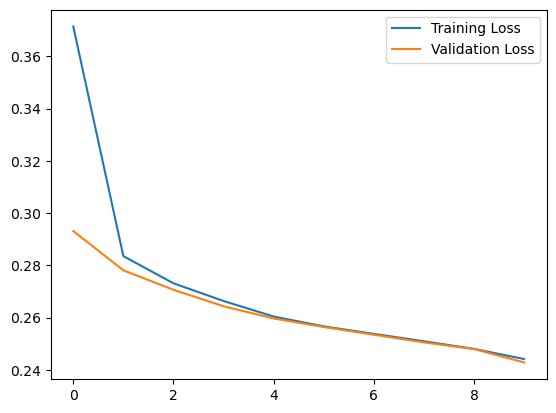

In [20]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.show()

In [21]:
x_test_reconstruct = model.predict(testX, verbose=0)

test_error = np.mean(np.square(testX - x_test_reconstruct),axis=(1, 2))

threshold = np.percentile(test_error, 95)
print("Threshold:", threshold)

Threshold: 0.38714044762544386


In [22]:

x_reconstruct = model.predict(X_windows, verbose=0)

reconstruction_error = np.mean(np.square(X_windows - x_reconstruct),axis=(1, 2))

y_pred = (reconstruction_error > threshold).astype(int)

In [23]:
print("Confusion Matrix:")
print(confusion_matrix(y_windows, y_pred))

print("\nClassification Report:")
print(classification_report(y_windows, y_pred))

Confusion Matrix:
[[15862   769]
 [ 2615  1376]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.95      0.90     16631
           1       0.64      0.34      0.45      3991

    accuracy                           0.84     20622
   macro avg       0.75      0.65      0.68     20622
weighted avg       0.82      0.84      0.82     20622

